In [1]:
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from astropy.nddata import Cutout2D
import numba

In [2]:
filename = '11072025/SP20250710224636.fits'

In [3]:
@numba.njit #вычитаем bias
def image_proc(data, bias):
    data_clear = np.zeros((5001, 1024, 1024))
    for i in range(len(data)):
        data_clear[i] = data[i] - bias
    return data_clear

In [4]:
biasfits = fits.open('11072025/SP20250710230021.fits')
data_bias = biasfits[0].data
avg_bias = np.average(data_bias, axis = 0)

In [5]:
WDS211935837_550 = fits.open(filename)
data5837_550 = WDS211935837_550[0].data 

In [6]:
# %load proc.py
from astropy.utils.iers import conf
conf.auto_max_age = None

from astroplan import Observer
from astropy.io import fits
import astropy.units as u
from astropy.coordinates import AltAz, EarthLocation, SkyCoord
from astropy.time import Time
from astropy.coordinates import ICRS
import numpy as np

data1 = fits.open(filename) #кадр со звездой

ra = data1[0].header['RAAPP']
dec = data1[0].header['DECAPP']
date = data1[0].header['DATE']

print(date)

coord_eq = SkyCoord(frame=ICRS, ra=float(ra), dec=float(dec), obstime=date, unit="deg")

longitude = data1[1].header['LONGITUD']
latitude = data1[1].header['LATITUDE']
loc = EarthLocation.from_geodetic(longitude,latitude)

utcoffset = 3*u.hour
time = Time(date)
#time = Time(date) + utcoffset

print(time)

coord_altaz = coord_eq.transform_to(AltAz(obstime=date, location=loc))
print(f"Altitude = {coord_altaz.alt:.2}")
print(f"Azimuth = {coord_altaz.az:.2}")
alt = coord_altaz.alt.value
KGO = Observer(location=loc, name="KGO")

parall = np.rad2deg(KGO.parallactic_angle(time, coord_eq)).value

print(parall)
print(alt)


2025-07-10T22:44:56
2025-07-10T22:44:56.000
Altitude = 7.4e+01 deg
Azimuth = 1.4e+01 deg
-160.9060553492595
74.26926708976389


In [7]:
eta = 132.9
rotate_angle = parall - alt + 90 + eta

In [8]:
rotate_angle

-12.27532243902337

In [18]:
#техническая информация
D = 2.5 * 0.5
scale = 0.02
lambda550 = WDS211935837_550[1].header.get('FILTLAM')
#lambdaI = WDS172373709_I[1].header.get('FILTLAM')
f_max550 = D / (lambda550 * 10**(-9)) / 206265
ID = 'second' # это то какая звезда опорная
OBJECT = WDS211935837_550[0].header['OBJECT']

In [10]:
data5837_550_clear = image_proc(data5837_550, avg_bias)
del data5837_550

In [11]:
OBJECT

'WDS21193+5837'

In [12]:
data5837_550_avg = np.average(data5837_550_clear, axis = 0)

In [16]:
# вырезаем нужные квадраты (автоматический режим)
from photutils.detection import find_peaks
from astropy.stats import sigma_clipped_stats
from scipy.ndimage import gaussian_filter
#ищем самые яркие писксели
mean, median, std = sigma_clipped_stats(data5837_550_avg, sigma=3.0)
data_smooth = gaussian_filter(data5837_550_avg, sigma=5.0) #гауссом убираем шумы
peaks = find_peaks(data_smooth, threshold=median + 5 * std, box_size=100)
x_init = peaks['x_peak']
y_init = peaks['y_peak']
lim1 = np.sqrt((x_init[0]-x_init[1])**2+(y_init[0]-y_init[1])**2)/1
lim2 = np.sqrt((x_init[0]-x_init[1])**2+(y_init[0]-y_init[1])**2)/1.5# это половина расстояния между звездами
cut_mask_first, cut_mask_second = np.zeros_like(data5837_550_clear[0], dtype=bool), np.zeros_like(data5837_550_clear[0], dtype=bool)
cutout_first = Cutout2D(data5837_550_avg, (x_init[0], y_init[0]), (lim1, lim1)) # первая звезда
cutout_second = Cutout2D(data5837_550_avg, (x_init[1], y_init[1]), (lim2, lim2)) # вторая зведа
x_min_first, x_max_first = cutout_first.slices_original[0].start, cutout_first.slices_original[0].stop #границы x1
y_min_first, y_max_first = cutout_first.slices_original[1].start, cutout_first.slices_original[1].stop #границы y1

x_min_second, x_max_second = cutout_second.slices_original[0].start, cutout_second.slices_original[0].stop #границы x2
y_min_second, y_max_second = cutout_second.slices_original[1].start, cutout_second.slices_original[1].stop #границы y2

cut_mask_first[x_min_first:x_max_first, y_min_first:y_max_first],  cut_mask_second[x_min_second:x_max_second, y_min_second:y_max_second] = True, True # макси для умножения
cut_mask = cut_mask_first + cut_mask_second


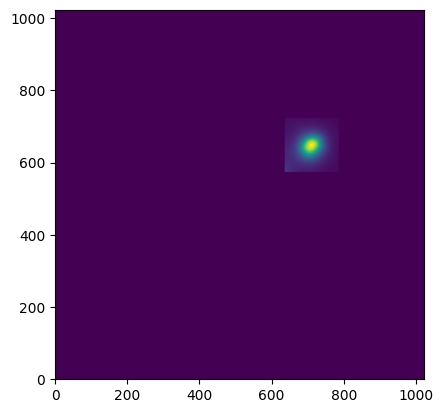

In [17]:
plt.imshow(data_smooth*cut_mask_second,  origin = 'lower')

#plt.scatter(x_init, y_init, marker = 'x')

In [19]:
def crop_nonzero_region(arr):

    if not np.any(arr):  # если все элементы нули
        return np.array([[]])  # или np.zeros((0, 0)) — на твой выбор

    nonzero_indices = np.argwhere(arr != 0)
    y_min, x_min = nonzero_indices.min(axis=0)
    y_max, x_max = nonzero_indices.max(axis=0) + 1  # включаем границы

    return arr[y_min:y_max, x_min:x_max]

In [20]:
N = 1000 # кол-во кадров по которым будем делать фурье
number_of_frames = data5837_550_clear.shape[0] - data5837_550_clear.shape[0] % 1000

In [26]:
import numpy as np

def center_pad_NHW(array: np.ndarray,
                   new_hw: tuple[int, int],
                   mode: str = 'constant',
                   constant_values=0) -> np.ndarray:
    """
    Паддинг для массива формы (N, H, W) до (N, H_new, W_new).

    Параметры
    ----------
    array : np.ndarray
        Входной массив размерности 3 (N, H, W).
    new_hw : tuple[int, int]
        Желаемые размеры по высоте и ширине (H_new, W_new).
    mode : str, optional
        Режим паддинга (см. np.pad), по умолчанию 'constant'.
    constant_values : scalar or tuple, optional
        Значение(я) для режима 'constant', по умолчанию 0.

    Возвращает
    -------
    np.ndarray
        Массив формы (N, H_new, W_new), в центре которого исходный array,
        периферия заполнена согласно mode/constant_values.
    """
    if array.ndim != 3:
        raise ValueError(f"Ожидается 3D-массив, получено ndim={array.ndim}")
    
    N, H, W = array.shape
    H_new, W_new = new_hw

    if H_new < H or W_new < W:
        raise ValueError(f"Новые размеры должны быть ≥ оригинальных: "
                         f"({H_new}, {W_new}) < ({H}, {W})")

    # Вычисляем отступы
    dh = H_new - H
    dw = W_new - W
    pad_h = (dh // 2, dh - dh // 2)
    pad_w = (dw // 2, dw - dw // 2)

    pad_width = (
        (0, 0),   # ось N не трогаем
        pad_h,    # высота
        pad_w     # ширина
    )

    return np.pad(array,
                  pad_width=pad_width,
                  mode=mode,
                  constant_values=constant_values)


In [21]:
ID

'second'

In [22]:
N = 1000 # кол-во кадров по которым будем делать фурье
number_of_frames = data5837_550_clear.shape[0] - data5837_550_clear.shape[0] % 1000 # общее кол-во кадров
iteration_frames = np.arange(0, number_of_frames, N)
for i, v in enumerate(iteration_frames):
    
    globals()['data_example_first_%s' % (i)] = np.zeros_like(np.stack([cutout_first.data] * N)) #это 1ая яркая звезда
    globals()['data_example_second_%s' % (i)]= np.zeros_like(np.stack([cutout_second.data] * N)) #это 2ая яркая звезда
    
    for j in range(v, v + N):
        globals()['data_example_first_%s' % (i)][j-v] = crop_nonzero_region(data5837_550_clear[j] * cut_mask_first)
        globals()['data_example_second_%s' % (i)][j-v] = crop_nonzero_region(data5837_550_clear[j] * cut_mask_second)

In [28]:
for i in range(int(number_of_frames / N)): 
    globals()['data_example_second_%s' % (i)] = center_pad_NHW(globals()['data_example_second_%s' % (i)], np.array(data_example_first_0.shape[1:]))

In [29]:
int(number_of_frames / N)

5

In [33]:
del data5837_550_clear

In [30]:
#делаем extent'ы
freq_sort = np.fft.fftshift(np.fft.fftfreq(data_example_first_0.shape[0])) / scale
extent_result = np.array([-data_example_first_0.shape[1]/2, data_example_first_0.shape[1]/2, -data_example_first_0.shape[2]/2, data_example_first_0.shape[2]/2]) * scale #секунды
extent_fourer = np.array([freq_sort[0], freq_sort[-1], freq_sort[0], freq_sort[-1]])  #частоты

In [31]:
def dOTF(z):
    z_abs = np.abs(z)
    result = np.where(z_abs < 1, (2 / np.pi) * (np.arccos(z) - z * np.sqrt(1 - z**2)), 0)
    return result

/var/folders/mc/0d9pt99j11z1dwp6zwvq3bvm0000gn/T/ipykernel_91847/2964407954.py:3: RuntimeWarning: invalid value encountered in arccos
  result = np.where(z_abs < 1, (2 / np.pi) * (np.arccos(z) - z * np.sqrt(1 - z**2)), 0)
/var/folders/mc/0d9pt99j11z1dwp6zwvq3bvm0000gn/T/ipykernel_91847/2964407954.py:3: RuntimeWarning: invalid value encountered in sqrt
  result = np.where(z_abs < 1, (2 / np.pi) * (np.arccos(z) - z * np.sqrt(1 - z**2)), 0)


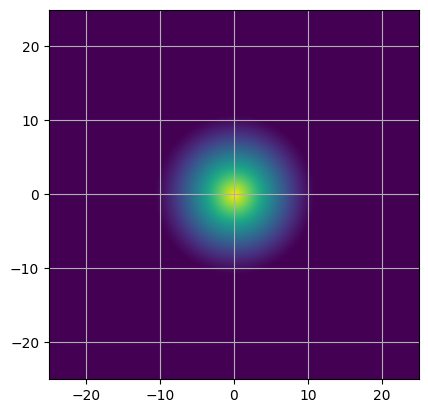

In [32]:
otf_data_in_x = np.abs(np.fft.fftshift(np.fft.fftfreq(data_example_first_0[0].shape[0])) / scale / f_max550)
otf_data_in_y = np.abs(np.fft.fftshift(np.fft.fftfreq(data_example_first_0[0].shape[0])) / scale / f_max550)
OTF_X, OTF_Y = np.meshgrid(otf_data_in_x , otf_data_in_y)
OTF_R = np.sqrt(OTF_X**2 + OTF_Y**2)
OTF_result = dOTF(OTF_R) # ОПФ, на которую будем умножать наш результат
plt.imshow(OTF_result, extent = extent_fourer)
plt.grid()

In [37]:
#2D фурье
for i in range(int(number_of_frames / N)): # сделать через глобалс
    fft_example_first = np.fft.fft2(globals()['data_example_first_%s' % (i)]) 
    fft_example_second = np.fft.fft2(globals()['data_example_second_%s' % (i)])
    #сдвигаем частоту в центра
    fft_final_first = np.fft.fftshift(fft_example_first)
    fft_final_second = np.fft.fftshift(fft_example_second)
    #просте деление не всегда хорошо -- можем делить на что-то очень близкое к 0
    '''
    fft_result = (fft_final_second) / (fft_final_first) #делим спектры
    fft_result[np.abs(fft_result) > 1000]=0 #зануляем выбросы
    '''
    # делаем маску с ограничением на максимальную частоту
    x1 = np.fft.fftshift(np.fft.fftfreq(fft_final_first[0].shape[0])) / scale
    y1 = np.fft.fftshift(np.fft.fftfreq(fft_final_first[0].shape[1])) / scale
    X1, Y1 = np.meshgrid(x1, y1)
    mask_round1 = np.sqrt(X1**2 + Y1**2) < f_max550
    x2 = np.fft.fftshift(np.fft.fftfreq(fft_final_second[0].shape[0])) / scale
    y2 = np.fft.fftshift(np.fft.fftfreq(fft_final_second[0].shape[1])) / scale
    X2, Y2 = np.meshgrid(x2, y2)
    mask_round2 = np.sqrt(X2**2 + Y2**2) < f_max550
    # решение проблемы: деление с весами
    if ID == 'second':
        power_spectrum = np.average(fft_final_second * np.conj(fft_final_second), axis = 0)
        #вычитаем подложку из спектра мощности
        mask_lines = np.ones_like(power_spectrum, dtype=bool) # линии из-за обрезки кадра
        mask_lines[0, :], mask_lines[:, 0] = False, False
        mask_lines = np.fft.fftshift(mask_lines)
        power_mask1 = mask_lines * ~mask_round2 # смотрим на область, где частота больше f_max
        average_power_spectrum = np.full(power_spectrum.shape, np.average(power_mask1 * power_spectrum)) # усредняем
        globals()['power_spectrum_corr_%s' % (i)] = power_spectrum - average_power_spectrum # вычитаем
        #итоговый результат
        fft_result_0 = np.average(fft_final_first * np.conj(fft_final_second), axis = 0) / globals()['power_spectrum_corr_%s' % (i)]
    elif ID == 'first':
        power_spectrum = np.average(fft_final_first * np.conj(fft_final_first), axis = 0)
        #вычитаем подложку из спектра мощности
        mask_lines = np.ones_like(power_spectrum, dtype=bool) # линии из-за обрезки кадра
        mask_lines[0, :], mask_lines[:, 0] = False, False
        mask_lines = np.fft.fftshift(mask_lines)
        power_mask1 = mask_lines * ~mask_round1 # смотрим на область, где частота больше f_max
        average_power_spectrum = np.full(power_spectrum.shape, np.average(power_mask1 * power_spectrum)) # усредняем
        globals()['power_spectrum_corr_%s' % (i)] = power_spectrum - average_power_spectrum # вычитаем
        #итоговый результат
        fft_result_0 = np.average(fft_final_second * np.conj(fft_final_first), axis = 0) / globals()['power_spectrum_corr_%s' % (i)]
    fft_result = fft_result_0 * OTF_result
    #зануляем,все что выше максимальной частоты
    #fft_result_masked = fft_result * mask_round
    
    #fft_result_final = np.fft.ifftshift(fft_result_masked) 
    globals()['result_final_%s' % (i)] = np.fft.ifftshift(np.fft.ifft2(fft_result))


In [38]:
#усредняем серии кадров, центрируя по самому яркому пикселю
accum = np.zeros_like(result_final_0, dtype = 'float')
for i in range(int(number_of_frames / N)):
    # центр изображения, к которому будем выравнивать
    img = np.abs(globals()['result_final_%s' % (i)])
    center = (result_final_0.shape[0]//2, result_final_0.shape[1]//2)
    
    y, x = np.unravel_index(np.argmax(img), img.shape)
    shift_y = center[0] - y
    shift_x = center[1] - x
    
    # сдвигаем и накапливаем
    img_shifted = np.roll(np.roll(img, shift_y, axis=0), shift_x, axis=1)
    accum += img_shifted
    
    # получаем окончательный результирующий образ
final_image = accum / (number_of_frames / N)

In [39]:
from scipy import ndimage
img_rot = ndimage.rotate(final_image, angle=rotate_angle,reshape=True)
img_final = img_rot[:, ::-1]

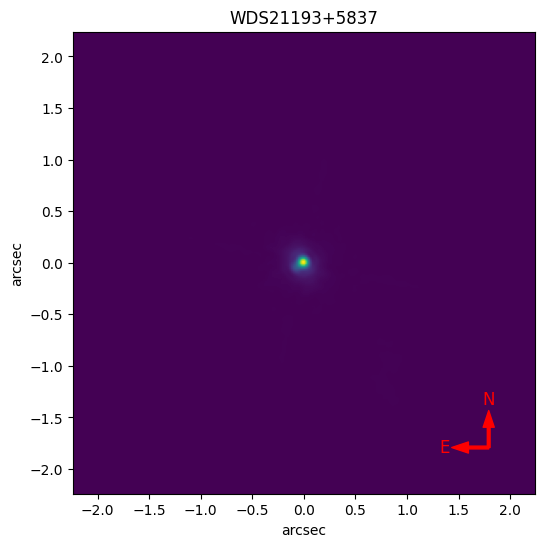

In [42]:
fig, ax = plt.subplots(figsize=(6, 6))
x0, y0 = 0.9, 0.1
# Ваше изображение
ax.imshow(img_final,  extent=extent_result, origin = 'lower')
ax.set_title(OBJECT)
ax.set_xlabel('arcsec')

ax.set_ylabel('arcsec')
# Стрелка "Север" остаётся без изменений
ax.annotate(
    '',
    xy=(x0, y0 + 0.08),    # конец стрелки (на 8% выше)
    xytext=(x0, y0),       # начало стрелки (общая точка)
    xycoords='axes fraction',
    arrowprops=dict(facecolor='red', edgecolor='red', width=2, headwidth=8)
)
ax.text(
    x0, y0 + 0.085, 'N',
    transform=ax.transAxes,
    ha='center', va='bottom',
    fontsize=12, color='red'
)

# Стрелка "Восток" (влево от точки)
ax.annotate(
    '',
    xy=(x0 - 0.08, y0),    # конец стрелки (на 8% левее)
    xytext=(x0, y0),       # начало стрелки (общая точка)
    xycoords='axes fraction',
    arrowprops=dict(facecolor='red', edgecolor='red', width=2, headwidth=8)
)
ax.text(
    x0 - 0.085, y0, 'E',
    transform=ax.transAxes,
    ha='right', va='center',
    fontsize=12, color='red'
)


plt.savefig('5837.pdf', bbox_inches='tight')


In [580]:
data_cut = np.zeros_like(np.stack([cutout_second.data] * data5837_550_clear.shape[0]))
for i in range(len(data_cut)):
    data_cut[i] = crop_nonzero_region(data5837_550_clear[i]*cut_mask_second)

In [581]:
#SAA

#усредняем серии кадров, центрируя по самому яркому пикселю
accum = np.zeros_like(data_cut[0], dtype = 'float')
for i in range(data_cut.shape[0]):
    img = data_cut[i]
    center = (data_cut.shape[1]//2, data_cut.shape[2]//2)
    
    y, x = np.unravel_index(np.argmax(img), img.shape)
    shift_y = center[0] - y
    shift_x = center[1] - x
    
    # сдвигаем и накапливаем
    img_shifted = np.roll(np.roll(img, shift_y, axis=0), shift_x, axis=1)
    accum += img_shifted
    
    # получаем окончательный результирующий образ
final_image = accum / data_cut.shape[0]

In [582]:
from scipy import ndimage
# Поворот на 45° по часовой стрелке (reshape=True расширяет массив, чтобы вместить весь повёрнутый объект)
img_rot = ndimage.rotate(final_image, angle=rotate_angle, reshape=True)
img_final = img_rot[:, ::-1]

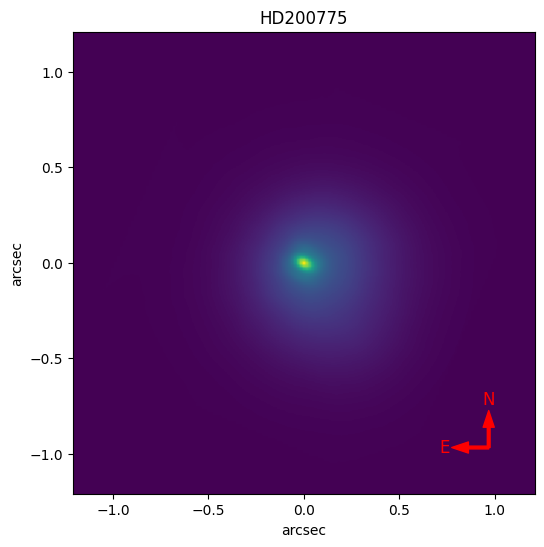

In [584]:
fig, ax = plt.subplots(figsize=(6, 6))
x0, y0 = 0.9, 0.1
# Ваше изображение
ax.imshow(img_final, extent=extent_result, origin = 'lower')
ax.set_title(OBJECT)
ax.set_xlabel('arcsec')

ax.set_ylabel('arcsec')
# Стрелка "Север" остаётся без изменений
ax.annotate(
    '',
    xy=(x0, y0 + 0.08),    # конец стрелки (на 8% выше)
    xytext=(x0, y0),       # начало стрелки (общая точка)
    xycoords='axes fraction',
    arrowprops=dict(facecolor='red', edgecolor='red', width=2, headwidth=8)
)
ax.text(
    x0, y0 + 0.085, 'N',
    transform=ax.transAxes,
    ha='center', va='bottom',
    fontsize=12, color='red'
)

# Стрелка "Восток" (влево от точки)
ax.annotate(
    '',
    xy=(x0 - 0.08, y0),    # конец стрелки (на 8% левее)
    xytext=(x0, y0),       # начало стрелки (общая точка)
    xycoords='axes fraction',
    arrowprops=dict(facecolor='red', edgecolor='red', width=2, headwidth=8)
)
ax.text(
    x0 - 0.085, y0, 'E',
    transform=ax.transAxes,
    ha='right', va='center',
    fontsize=12, color='red'
)


plt.savefig('HD_SAA.pdf', bbox_inches='tight')


In [586]:
%reset

Once deleted, variables cannot be recovered. Proceed (y/[n])?  y
